# 2.2 Multivariate regression

Same target (`monthly_spend`), now with the full feature block plus a
categorical predictor (`region`, via dummy variables). Least squares,
predictor selection (adjusted R², AIC), and residual diagnostics
(autocorrelation, multicollinearity).

## Setup

Throughout this notebook (and every other notebook in this folder) we reuse
the **same 300-row synthetic customer table** (`data/customers.csv`, see
`data/generate_customers.py`): a small telecom/subscription dataset with a
continuous target (`monthly_spend`) for regression notebooks and a binary
target (`churned`) for classification notebooks, plus a block of numeric
features used for resampling, evaluation-metric, dimensionality-reduction
and clustering demos. The point isn't the dataset -- it's small and
synthetic on purpose -- the point is seeing each technique applied to
something you already recognise from the last notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("common"))
sys.path.insert(0, os.path.abspath("../common"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

CUSTOMERS_PATH = "data/customers.csv" if os.path.exists("data/customers.csv") else "../data/customers.csv"
df = pd.read_csv(CUSTOMERS_PATH)
df.head()

,customer_id,age,region,tenure_months,income_k,monthly_usage,support_calls,discount_pct,satisfaction,monthly_spend,churned
0,C0001,45.7,South,90.7,78.1,8.3,2,0,8.12,39.35,0
1,C0002,29.5,North,54.9,58.4,27.3,6,5,5.80,51.69,0
2,C0003,51.0,West,28.6,73.3,13.9,5,0,5.48,37.75,1
3,C0004,53.3,West,22.9,106.5,13.3,6,10,9.25,34.31,1
4,C0005,18.6,West,45.7,35.5,67.2,6,15,7.26,52.28,0


In [2]:
from sklearn.model_selection import train_test_split

numeric_features = ["age","tenure_months","income_k","monthly_usage","support_calls","discount_pct","satisfaction"]
df_enc = pd.get_dummies(df, columns=["region"], drop_first=True)  # dummy variables, one region dropped as baseline
dummy_cols = [c for c in df_enc.columns if c.startswith("region_")]
all_features = numeric_features + dummy_cols

Xtr, Xte, ytr, yte = train_test_split(df_enc[all_features], df_enc["monthly_spend"], test_size=0.3, random_state=0)
df_enc[dummy_cols].head()

,region_North,region_South,region_West
0,False,True,False
1,True,False,False
2,False,False,True
3,False,False,True
4,False,False,True


In [3]:
# statsmodels gives readable coefficient/summary tables; install if missing
try:
    import statsmodels
except ImportError:
    %pip install -q statsmodels

## Estimation: least squares (statsmodels, for readable coefficient tables)

In [4]:
import statsmodels.api as sm

Xtr_c = sm.add_constant(Xtr)
full_model = sm.OLS(ytr.astype(float), Xtr_c.astype(float)).fit()
print(full_model.summary().tables[1])

                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            15.8148      3.826      4.133      0.000       8.270      23.360
age               0.0320      0.045      0.711      0.478      -0.057       0.121
tenure_months     0.1225      0.019      6.306      0.000       0.084       0.161
income_k          0.0912      0.024      3.825      0.000       0.044       0.138
monthly_usage     0.5699      0.031     18.441      0.000       0.509       0.631
support_calls     0.2739      0.244      1.124      0.263      -0.207       0.754
discount_pct     -0.3152      0.072     -4.390      0.000      -0.457      -0.174
satisfaction      0.1001      0.369      0.271      0.787      -0.628       0.828
region_North     -1.2030      1.194     -1.007      0.315      -3.558       1.152
region_South     -0.4402      1.178     -0.374      0.709      -2.764       1.883
region_West     

`region` enters as dummy variables (one category dropped as the baseline)
-- each dummy's coefficient is the average spend difference vs. that
baseline region, holding the other features fixed, exactly the "extra
predictors: dummy variables" idea from the slides.

## Selecting predictors: comparing subsets

In [5]:
def fit_and_score(feature_subset):
    Xtr_sub = sm.add_constant(Xtr[feature_subset].astype(float))
    m = sm.OLS(ytr.astype(float), Xtr_sub).fit()
    return m.rsquared_adj, m.aic

candidates = {
    "usage only": ["monthly_usage"],
    "usage + income": ["monthly_usage", "income_k"],
    "usage + income + tenure": ["monthly_usage", "income_k", "tenure_months"],
    "all numeric": numeric_features,
    "all numeric + region": all_features,
}
rows = []
for name, feats in candidates.items():
    adj_r2, aic = fit_and_score(feats)
    rows.append({"model": name, "n_predictors": len(feats), "adj_R2": round(adj_r2, 3), "AIC": round(aic, 1)})
pd.DataFrame(rows)

,model,n_predictors,adj_R2,AIC
0,usage only,1,0.574,1420.7
1,usage + income,2,0.600,1408.8
2,usage + income + tenure,3,0.659,1376.0
3,all numeric,7,0.685,1363.1
4,all numeric + region,10,0.685,1366.5


Plain R² can only go up as you add predictors (even useless ones) -- that's
why the slides reach for **adjusted R²** (penalises extra predictors) and
**AIC** (lower is better, also penalises complexity) instead of chasing raw
R². Best-subset/stepwise search is the same idea automated: try many
subsets, keep the one that wins on a penalised criterion, not on raw fit.

## Residual diagnostics: autocorrelation and multicollinearity

In [6]:
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor

full_model_all = sm.OLS(ytr.astype(float), sm.add_constant(Xtr[all_features].astype(float))).fit()
dw = durbin_watson(full_model_all.resid)
print(f"Durbin-Watson statistic: {dw:.2f}  (near 2 = little autocorrelation; well below 2 = positive autocorrelation)")

vif = pd.DataFrame({
    "feature": numeric_features,
    "VIF": [variance_inflation_factor(Xtr[numeric_features].astype(float).values, i) for i in range(len(numeric_features))],
})
vif.sort_values("VIF", ascending=False)

Durbin-Watson statistic: 2.04  (near 2 = little autocorrelation; well below 2 = positive autocorrelation)


,feature,VIF
0,age,1.339858
2,income_k,1.323782
4,support_calls,1.176869
1,tenure_months,1.139994
6,satisfaction,1.068617
5,discount_pct,1.034575
3,monthly_usage,1.032111


A VIF well above 5-10 for a feature flags it as (nearly) a linear
combination of the others -- multicollinearity making its own coefficient
unstable/hard to interpret, even if the model's overall fit still looks
fine.

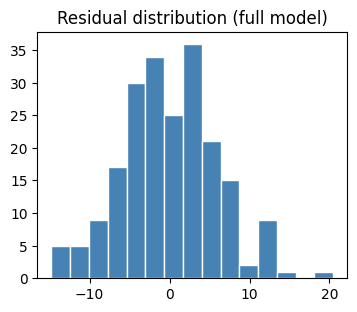

In [7]:
resid = ytr - full_model_all.predict(sm.add_constant(Xtr[all_features].astype(float)))
fig, ax = plt.subplots(figsize=(4, 3.2))
ax.hist(resid, bins=15, color="steelblue", edgecolor="white")
ax.set_title("Residual distribution (full model)")
plt.show()

**Takeaway**: more predictors almost always fit the training data better,
but adjusted R²/AIC and the VIF/autocorrelation checks are what keep that
from becoming overfitting or an uninterpretable, unstable model.